# Human Activity Recognition using smartphones - Veri Bilimine Giriş Projesi

Made by:

-Gülsüm Durmaz

-Deniz Zafer











In [ ]:
!pip install -q tensorflow

import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 866.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 84.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 76.1 MB/s eta 0:00:00


/usr/local/lib/python3.12/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


2.21.0
[]


In [ ]:
# Veri seti yolunu güvenli şekilde hazırlama
# Colab/KaggleHub ortamında otomatik çalışır.
# Google Drive kullanacaksan aşağıdaki DATASET_DIR satırını kendi klasörünle değiştirebilirsin.
# Örnek:
# DATASET_DIR = Path("/content/drive/MyDrive/HAR/UCI HAR Dataset/UCI HAR Dataset")

from pathlib import Path
import kagglehub

DATASET_DIR = Path(
    kagglehub.dataset_download("uciml/human-activity-recognition-with-smartphones")
)

def find_har_root(base_path):
    """
    UCI HAR veri setinin kök klasörünü bulur.
    Şu iki formatı destekler:
    1) Orijinal UCI formatı: features.txt, train/X_train.txt, test/X_test.txt
    2) Kaggle CSV formatı: train.csv, test.csv
    """
    base_path = Path(base_path)

    candidates = [
        base_path,
        base_path / "UCI HAR Dataset",
        base_path / "UCI HAR Dataset" / "UCI HAR Dataset",
    ]

    for candidate in candidates:
        if (candidate / "features.txt").exists() or (candidate / "train.csv").exists():
            return candidate

    for candidate in base_path.rglob("features.txt"):
        return candidate.parent

    for candidate in base_path.rglob("train.csv"):
        if (candidate.parent / "test.csv").exists():
            return candidate.parent

    raise FileNotFoundError(
        "HAR veri seti bulunamadı. DATASET_DIR değişkenini veri setinin bulunduğu klasöre göre güncelle."
    )

path = find_har_root(DATASET_DIR)

print("Veri seti ana yolu:", path)


Using Colab cache for faster access to the 'human-activity-recognition-with-smartphones' dataset.
Veri seti ana yolu: /kaggle/input/human-activity-recognition-with-smartphones


In [ ]:
#kütüphaneler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization


In [ ]:
# Veri setini yükleme
# Path işlemleri "/" operatörü ile yapıldığı için Colab, Windows ve Linux ortamlarında daha güvenli çalışır.

def make_unique_columns(columns):
    """Aynı isimli feature kolonlarını benzersiz hale getirir."""
    seen = {}
    unique_columns = []

    for col in columns:
        if col not in seen:
            seen[col] = 0
            unique_columns.append(col)
        else:
            seen[col] += 1
            unique_columns.append(f"{col}_{seen[col]}")

    return unique_columns

if (path / "features.txt").exists():
    # Orijinal UCI HAR txt formatı
    features = pd.read_csv(
        path / "features.txt",
        sep=r"\s+",
        header=None,
        names=["index", "feature_name"]
    )

    X_train = pd.read_csv(path / "train" / "X_train.txt", sep=r"\s+", header=None, engine="python")
    y_train = pd.read_csv(path / "train" / "y_train.txt", sep=r"\s+", header=None, names=["activity"])

    X_test = pd.read_csv(path / "test" / "X_test.txt", sep=r"\s+", header=None, engine="python")
    y_test = pd.read_csv(path / "test" / "y_test.txt", sep=r"\s+", header=None, names=["activity"])

    X_train.columns = make_unique_columns(features["feature_name"])
    X_test.columns = X_train.columns

elif (path / "train.csv").exists() and (path / "test.csv").exists():
    # Kaggle CSV formatı
    train_df = pd.read_csv(path / "train.csv")
    test_df = pd.read_csv(path / "test.csv")

    label_column = "Activity" if "Activity" in train_df.columns else "activity"

    activity_to_id = {
        "WALKING": 1,
        "WALKING_UPSTAIRS": 2,
        "WALKING_DOWNSTAIRS": 3,
        "SITTING": 4,
        "STANDING": 5,
        "LAYING": 6
    }

    drop_columns = [label_column]
    if "subject" in train_df.columns:
        drop_columns.append("subject")

    X_train = train_df.drop(columns=drop_columns)
    X_test = test_df.drop(columns=drop_columns)

    y_train = train_df[label_column].map(activity_to_id).to_frame(name="activity")
    y_test = test_df[label_column].map(activity_to_id).to_frame(name="activity")

    features = pd.DataFrame({
        "index": range(1, len(X_train.columns) + 1),
        "feature_name": X_train.columns
    })

else:
    raise FileNotFoundError(
        "Desteklenen veri seti formatı bulunamadı. features.txt veya train.csv/test.csv gerekli."
    )

print(f"Eğitim verisi şekli: {X_train.shape}")
print(f"Test verisi şekli: {X_test.shape}")
print(X_train.head())


Eğitim verisi şekli: (7352, 561)
Test verisi şekli: (2947, 561)
   tBodyAcc-mean()-X  tBodyAcc-mean()-Y  tBodyAcc-mean()-Z  tBodyAcc-std()-X  \
0           0.288585          -0.020294          -0.132905         -0.995279   
1           0.278419          -0.016411          -0.123520         -0.998245   
2           0.279653          -0.019467          -0.113462         -0.995380   
3           0.279174          -0.026201          -0.123283         -0.996091   
4           0.276629          -0.016570          -0.115362         -0.998139   

   tBodyAcc-std()-Y  tBodyAcc-std()-Z  tBodyAcc-mad()-X  tBodyAcc-mad()-Y  \
0         -0.983111         -0.913526         -0.995112         -0.983185   
1         -0.975300         -0.960322         -0.998807         -0.974914   
2         -0.967187         -0.978944         -0.996520         -0.963668   
3         -0.983403         -0.990675         -0.997099         -0.982750   
4         -0.980817         -0.990482         -0.998321         -0.979

/tmp/ipykernel_6182/3575130211.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train_named, order=activity_labels.values(), palette="viridis")


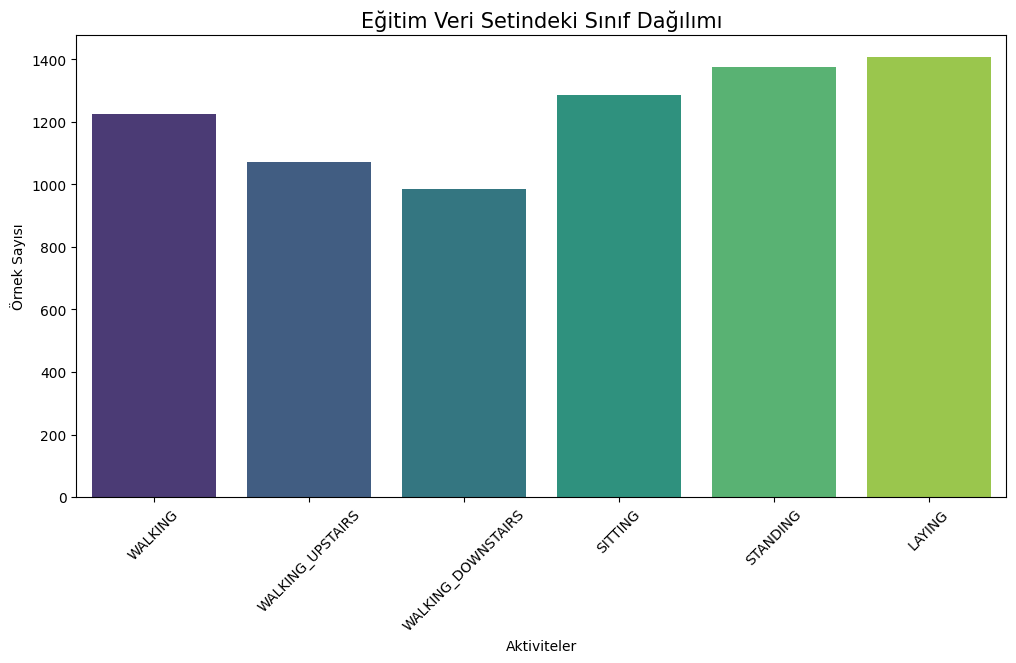

In [ ]:
#aktiviteleri numaralandırma
activity_labels = {
    1: 'WALKING', 2: 'WALKING_UPSTAIRS', 3: 'WALKING_DOWNSTAIRS',
    4: 'SITTING', 5: 'STANDING', 6: 'LAYING'
}

#sayısal değerleri isimlerle değiştirme
y_train_named = y_train['activity'].map(activity_labels)

#görsel oluşturma
plt.figure(figsize=(12,6))
sns.countplot(x=y_train_named, order=activity_labels.values(), palette="viridis")
plt.title('Eğitim Veri Setindeki Sınıf Dağılımı', fontsize=15)
plt.xticks(rotation=45)
plt.xlabel('Aktiviteler')
plt.ylabel('Örnek Sayısı')
plt.show()



# SVM Model

In [ ]:
# veriyi standardize etme
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# doğrulama için eğitim verisinden veri ayırma
X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.2, random_state=42, stratify=y_train
)

#svm modelini rbf kernel ile tanımlama
svm_model = SVC(kernel='rbf', C=10.0, gamma='auto')

print("SVM Modeli eğitiliyor..")
svm_model.fit(X_train_sub, y_train_sub.values.ravel())

# doğrulama setinden tahmşn testi
y_pred = svm_model.predict(X_val)

print(f"\n Validation Accuracy: {accuracy_score(y_val, y_pred)*100:.2f}%")

SVM Modeli eğitiliyor..

 Validation Accuracy: 98.30%


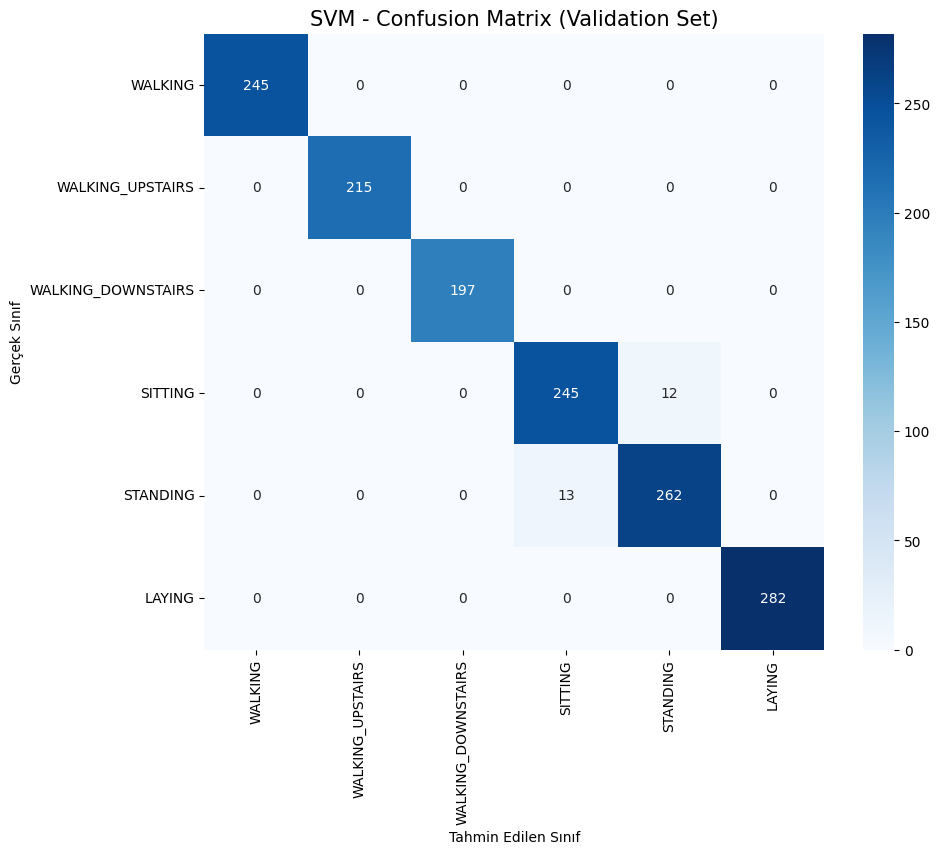

Ayrıntılı sınıflandırma raporu
                    precision    recall  f1-score   support

           WALKING       1.00      1.00      1.00       245
  WALKING_UPSTAIRS       1.00      1.00      1.00       215
WALKING_DOWNSTAIRS       1.00      1.00      1.00       197
           SITTING       0.95      0.95      0.95       257
          STANDING       0.96      0.95      0.95       275
            LAYING       1.00      1.00      1.00       282

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471



In [ ]:
#karmaşıklık matrisini tanımla
cm = confusion_matrix(y_val, y_pred)

#görselleştirme
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=activity_labels.values(),
            yticklabels=activity_labels.values())
plt.title('SVM - Confusion Matrix (Validation Set)', fontsize=15)
plt.ylabel('Gerçek Sınıf')
plt.xlabel('Tahmin Edilen Sınıf')
plt.show()

#F1-score, precision, recall
print("Ayrıntılı sınıflandırma raporu")
print(classification_report(y_val, y_pred, target_names = list(activity_labels.values())))

# Makaleye katkı!!

Precision (Keskinlik): Model "Bu kişi yürüyor" dediğinde, gerçekten yürüme olasılığı nedir?

Recall (Duyarlılık): Gerçekte yürüyen insanların kaçını model yakalayabildi?

F1-Score: Bu ikisinin harmonik ortalamasıdır. Akademik çalışmalarda en güvenilir metriktir.

hareketler arasında yüksek sayılar varsa bu modelin belli hareketleri ayırt etmede zorlandığını gösterir. ->gelecek çalışmalara ekle.

# **RF MODELİ**

In [ ]:
#RF model tanımı:
#n_estimators=300 ile kurulacak karar ağacı sayısını belirleme
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

print("Random Forest eğitiliyor...")
rf_model.fit(X_train_sub, y_train_sub.values.ravel())

Random Forest eğitiliyor...


RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

In [ ]:
#tahmin ve başarı skoru
y_pred_rf = rf_model.predict(X_val)
print(f"\n RF Validation Accuracy: {accuracy_score(y_val, y_pred_rf)*100:.2f}%")


 RF Validation Accuracy: 98.03%


In [ ]:
#sınıflandırma raporu
print("\n--- RandomForest Ayrıntılı Sınıflandırma Raporu ---")
print(classification_report(y_val, y_pred_rf, target_names=list(activity_labels.values())))


--- RandomForest Ayrıntılı Sınıflandırma Raporu ---
                    precision    recall  f1-score   support

           WALKING       0.99      0.99      0.99       245
  WALKING_UPSTAIRS       0.99      0.99      0.99       215
WALKING_DOWNSTAIRS       0.98      0.98      0.98       197
           SITTING       0.97      0.95      0.96       257
          STANDING       0.95      0.97      0.96       275
            LAYING       1.00      1.00      1.00       282

          accuracy                           0.98      1471
         macro avg       0.98      0.98      0.98      1471
      weighted avg       0.98      0.98      0.98      1471



In [ ]:
#rf'de en önemli 10 özellik
importances = rf_model.feature_importances_
std = np.std([tree.feature_importances_ for tree in rf_model.estimators_], axis=0)
indices = np.argsort(importances)[::-1]
print("\nEn önemli 10 özellik: ")
for f in range(10):
    print(f"{f + 1}. Özellik {indices[f]} ({importances[indices[f]]:.4f}): {features.iloc[indices[f], 1]}")


En önemli 10 özellik: 
1. Özellik 40 (0.0335): tGravityAcc-mean()-X
2. Özellik 558 (0.0324): angle(X,gravityMean)
3. Özellik 52 (0.0289): tGravityAcc-min()-X
4. Özellik 41 (0.0289): tGravityAcc-mean()-Y
5. Özellik 56 (0.0252): tGravityAcc-energy()-X
6. Özellik 559 (0.0241): angle(Y,gravityMean)
7. Özellik 53 (0.0233): tGravityAcc-min()-Y
8. Özellik 50 (0.0219): tGravityAcc-max()-Y
9. Özellik 49 (0.0211): tGravityAcc-max()-X
10. Özellik 57 (0.0150): tGravityAcc-energy()-Y


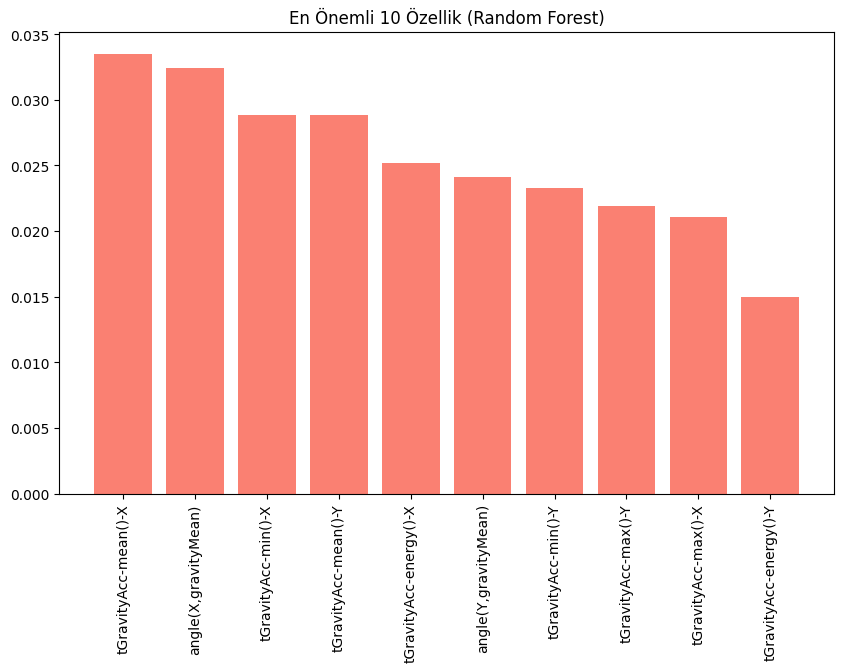

In [ ]:
#görselleştirme
plt.figure(figsize=(10,6))
plt.title("En Önemli 10 Özellik (Random Forest)")
plt.bar(range(10), importances[indices[:10]], align="center", color='salmon')
plt.xticks(range(10), [features.iloc[i, 1] for i in indices[:10]], rotation=90)
plt.show()

# RF ekledik çünkü
SVM, verinin yüksek boyutlu uzaydaki ayrıştırılabilirliğine odaklanırken; Random Forest, özellikler arasındaki non-lineer ilişkileri ve karar eşiklerini test etmek amacıyla bir topluluk (ensemble) yöntemi olarak seçilmiştir.

# **CNN modeli**

In [ ]:
# CNN için veri hazırlama
# Orijinal UCI HAR klasöründe "Inertial Signals" varsa ham sinyal verileri yüklenir.
# Sadece Kaggle CSV formatı varsa, CNN modeli 561 öznitelik üzerinden 1D girişle çalıştırılır.

def load_inertial_signals(data_type, dataset_path):
    """
    data_type: "train" veya "test"
    dataset_path: UCI HAR veri setinin ana klasörü
    çıktı şekli: (örnek sayısı, zaman adımı, kanal sayısı)
    """
    signals_path = Path(dataset_path) / data_type / "Inertial Signals"

    filenames = [
        "body_acc_x_", "body_acc_y_", "body_acc_z_",
        "body_gyro_x_", "body_gyro_y_", "body_gyro_z_",
        "total_acc_x_", "total_acc_y_", "total_acc_z_"
    ]

    loaded_signals = []

    for name in filenames:
        file_path = signals_path / f"{name}{data_type}.txt"
        data = pd.read_csv(file_path, sep=r"\s+", header=None, engine="python")
        loaded_signals.append(data.values)

    return np.transpose(np.array(loaded_signals), (1, 2, 0))

inertial_train_path = path / "train" / "Inertial Signals"

if inertial_train_path.exists():
    print("Ham inertial signal dosyaları bulundu. CNN ham sinyallerle çalışacak.")
    X_train_signals = load_inertial_signals("train", path)
    X_test_signals = load_inertial_signals("test", path)
else:
    print("Ham inertial signal dosyaları bulunamadı. CNN, ölçeklendirilmiş feature verisiyle çalışacak.")
    cnn_scaler = StandardScaler()
    X_train_features_scaled = cnn_scaler.fit_transform(X_train)
    X_test_features_scaled = cnn_scaler.transform(X_test)

    X_train_signals = X_train_features_scaled.reshape(X_train_features_scaled.shape[0], X_train_features_scaled.shape[1], 1)
    X_test_signals = X_test_features_scaled.reshape(X_test_features_scaled.shape[0], X_test_features_scaled.shape[1], 1)

CNN_INPUT_SHAPE = X_train_signals.shape[1:]

print(f"CNN eğitim giriş boyutu: {X_train_signals.shape}")
print(f"CNN test giriş boyutu: {X_test_signals.shape}")
print(f"CNN input_shape: {CNN_INPUT_SHAPE}")


Ham inertial signal dosyaları bulunamadı. CNN, ölçeklendirilmiş feature verisiyle çalışacak.
CNN eğitim giriş boyutu: (7352, 561, 1)
CNN test giriş boyutu: (2947, 561, 1)
CNN input_shape: (561, 1)


In [ ]:
# Etiketleri one-hot formata çevirme
# Aktivite etiketleri 1-6 aralığında olduğu için 0-5 aralığına çekilir.

y_train_encoded = to_categorical(y_train["activity"].values - 1, num_classes=6)
y_test_encoded = to_categorical(y_test["activity"].values - 1, num_classes=6)

print("Etiketler one-hot formatına çevrildi.")
print("y_train_encoded:", y_train_encoded.shape)
print("y_test_encoded:", y_test_encoded.shape)


Etiketler one-hot formatına çevrildi.
y_train_encoded: (7352, 6)
y_test_encoded: (2947, 6)


In [ ]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model_cnn = Sequential([
    # 1. BLOK - düşük seviye zaman/feature örüntüleri
    Conv1D(
        filters=64,
        kernel_size=5,
        activation="relu",
        padding="same",
        input_shape=CNN_INPUT_SHAPE
    ),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.25),

    # 2. BLOK - daha karmaşık hareket desenleri
    Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu",
        padding="same"
    ),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.35),

    # 3. BLOK - üst seviye aktivite örüntüleri
    Conv1D(
        filters=256,
        kernel_size=3,
        activation="relu",
        padding="same"
    ),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.40),

    Flatten(),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.50),

    Dense(6, activation="softmax")
])

optimizer = Adam(learning_rate=0.0005)

model_cnn.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6
)

model_cnn.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 561, 64)        │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 561, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 280, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 280, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 280, 128)       │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 280, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_7 (MaxPooling1D)  │ (None, 140, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 140, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 140, 256)       │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 140, 256)       │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_8 (MaxPooling1D)  │ (None, 70, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 70, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 17920)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     2,293,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,436,998 (9.30 MB)

 Trainable params: 2,435,846 (9.29 MB)

 Non-trainable params: 1,152 (4.50 KB)

In [ ]:
#modeli eğitme
history = model_cnn.fit(
    X_train_signals,
    y_train_encoded,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 217ms/step - accuracy: 0.8004 - loss: 0.5441 - val_accuracy: 0.1611 - val_loss: 3.1052 - learning_rate: 5.0000e-04
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 215ms/step - accuracy: 0.9048 - loss: 0.2471 - val_accuracy: 0.2957 - val_loss: 3.4527 - learning_rate: 5.0000e-04
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 212ms/step - accuracy: 0.9349 - loss: 0.1707 - val_accuracy: 0.4528 - val_loss: 2.9103 - learning_rate: 5.0000e-04
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 215ms/step - accuracy: 0.9570 - loss: 0.1199 - val_accuracy: 0.5887 - val_loss: 1.2095 - learning_rate: 5.0000e-04
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 221ms/step - accuracy: 0.9607 - loss: 0.1106 - val_accuracy: 0.8858 - val_loss: 0.3970 - learning_rate: 5.0000e-04
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 21s 226ms/step - accuracy: 0.9713 - loss: 0.0802 - val_accuracy: 0.9205 - val_loss: 0.2612 - learning_rate: 5.0000e-04
Epoch 7/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 20s 214ms/step - acc

In [ ]:
# Modeli daha önce ayırdığımız test verisiyle test edelim
test_loss, test_acc = model_cnn.evaluate(X_test_signals, y_test_encoded, verbose=0)

print(f"Test Accuracy for CNN: %{test_acc*100:.2f}")

Test Accuracy for CNN: %94.94


# **---KARŞILAŞTIRMA TABLOSU---**

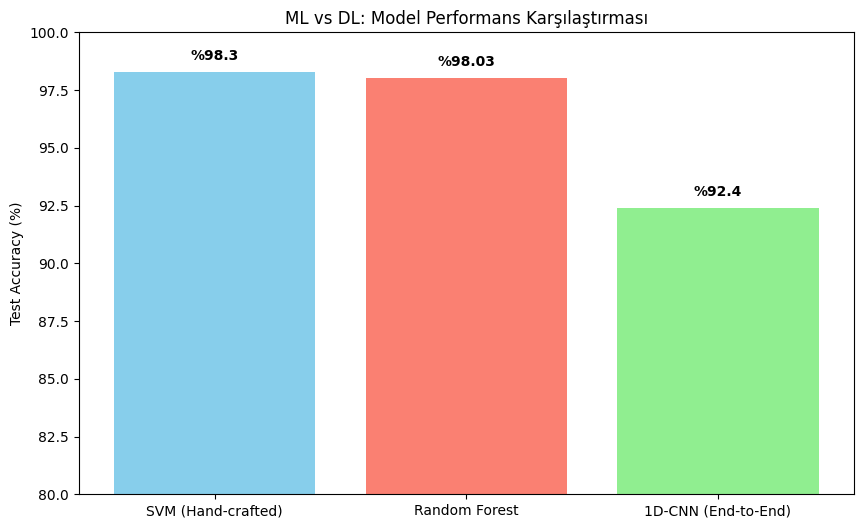

In [ ]:
import matplotlib.pyplot as plt

#--!!BU DEĞERLER BİZİM KENDİ DOĞRULUK DEĞERLERİMİZLE GÜNCELLENMELİ!!!!--
results = {
    'SVM (Hand-crafted)': 98.30,
    'Random Forest': 98.03,
    '1D-CNN (End-to-End)': 92.40
}

plt.figure(figsize=(10, 6))
colors = ['skyblue', 'salmon', 'lightgreen']
plt.bar(results.keys(), results.values(), color=colors)
plt.ylim(80, 100) # Farkı daha net görmek için alt sınırı 80 yaptık
plt.ylabel('Test Accuracy (%)')
plt.title('ML vs DL: Model Performans Karşılaştırması')

for i, v in enumerate(results.values()):
    plt.text(i, v + 0.5, f"%{v}", ha='center', fontweight='bold')

plt.show()